### **VP_Constant**

**Paso 1: Cargamos los datos**

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np

from functools import partial 

import torch
from torch.utils.data import (
    DataLoader,
    Dataset,
    Subset,
)
from torchvision import datasets
from torchvision.transforms import ToTensor
from torchvision.transforms import functional
from noise_schedules import linear_schedule, cosine_schedule

import difussion_process_conditional as dfpc
import ode_condicional as odec

from diffusion_utilities import (
    plot_image_grid,
    plot_image_evolution,
    animation_images,
    colorize_mnist
)


n_threads = torch.get_num_threads()
print('Number of threads: {:d}'.format(n_threads))

device ='cuda' #with cuda should be faster
#device ='cpu' 

colored = True

Number of threads: 6


In [2]:
import torchvision.transforms as T
if not colored:
    transform = ToTensor()
    n_channels = 1
else:
    # Convierte a (1, H, W) y luego colorea a (3, H, W)
    transform = T.Compose([
        ToTensor(),
        T.Lambda(colorize_mnist),
    ])
    n_channels = 3
data = datasets.MNIST(
    root='data',
    train=True,
    download=True,
    transform=transform,
)
print(type(data))

<class 'torchvision.datasets.mnist.MNIST'>


In [3]:
# Create a subset dataset composed of only images of one of the digits
digit1 = 3
digit2 = 8
indices_digit = torch.where(
    (data.targets == digit1) | (data.targets == digit2)
)[0]
#indices_digit = torch.where(data.targets == digit1)[0]  

data_train = data
#data_train = data
print(type(data_train))

<class 'torchvision.datasets.mnist.MNIST'>


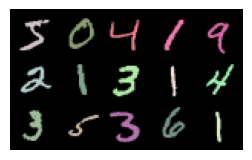

In [4]:
# Visualize training images
n_rows = 3 
n_cols = 5

_ = plot_image_grid(
    images=[data_train[i][0] for i in range(n_rows * n_cols)],
    figsize =(3, 3),
    n_rows=n_rows, 
    n_cols=n_cols,
)

**Probamos primero con Variance Perserving**

In [5]:
T = 1.0
beta_min = 0.1
beta_max = 20.0

def linear_beta(t):
    """Linear beta schedule for VP-SDE."""
    return beta_min + t * (beta_max - beta_min)

def vp_drift_coefficient(x_t, t):
    beta = linear_beta(t) 
    beta_reshaped = beta.view(-1,1,1,1)
    return -0.5 * beta_reshaped * x_t

def vp_diffusion_coefficient(t):
    beta = linear_beta(t) 
    beta_reshaped = beta.view(-1,1,1,1)
    return torch.sqrt(beta_reshaped + 1e-8)

def vp_mu_t(x_0, t):
    # For a linear beta schedule, integral is beta_min*t + 0.5*(beta_max-beta_min)*t^2
    integral_beta = beta_min * t + 0.5 * (t**2) * (beta_max - beta_min)
    alpha = torch.exp(-integral_beta)
    alpha_reshaped = alpha.view(-1, 1, 1, 1)
    return x_0 * torch.sqrt(alpha_reshaped + 1e-8)

def vp_sigma_t(t):
    if not torch.is_tensor(t):
        t = torch.tensor(t)
    integral_beta = beta_min * t + 0.5 * (t**2) * (beta_max - beta_min)
    alpha = torch.exp(-integral_beta)
    return torch.sqrt(1.0 - alpha + 1e-8)

def vp_marginal_prob_std(t):
    return vp_sigma_t(t)
    
drift_coefficient = vp_drift_coefficient
diffusion_coefficient = partial(vp_diffusion_coefficient)
mu_t = vp_mu_t
sigma_t = partial(vp_sigma_t)


diffusion_process = dfpc.GaussianDiffussionProcess(
    drift_coefficient,
    diffusion_coefficient,
    mu_t,
    sigma_t,
)


In [6]:
# Define the score model

from score_model import ScoreNet

score_model = torch.nn.DataParallel(
    ScoreNet(
        marginal_prob_std=vp_marginal_prob_std,
        num_classes = 10,
        input_channels = n_channels
    )
)
score_model = score_model.to(device)

In [87]:
# Train model
from torch.optim import Adam
import torchvision.transforms as transforms
from tqdm.auto import tqdm, trange
batch_size = 64
data_loader = DataLoader(
    data_train, 
    batch_size=batch_size, 
    shuffle=True, 
    num_workers=n_threads,
)

# Load the model from the checkpoint
checkpoint = torch.load('check_point_constant.pth')
score_model.load_state_dict(checkpoint)

#  [TO DO: Comment each line of code]
#establish learning rate, which controls the size of the weights
learning_rate = 2e-4  
# We create Adam optimizer which adjusts automatically the learning rate for each parameter. 
# score_model, tells the optimizer which weights to use
# lr, defines the learning rate
optimizer = Adam(score_model.parameters(), lr=learning_rate)
n_epochs = 25 #Number of epochs for training
tqdm_epoch = trange(n_epochs) #creates a progress bar to see the progress of the training
for epoch in tqdm_epoch: 
    avg_loss = 0.0 #Initial average loss
    num_items = 0 #Number of images processed in an epoch
    for x, y in data_loader: #for each bacth the data_loader
        x = x.to(device) #images to cpu or gpu for PyTorch to process them
        y = y.to(device)
        loss = diffusion_process.loss_function(score_model, x, y) #loss for the batch
        optimizer.zero_grad() #reboot gradients to zero (if not they acumulate)
        loss.backward() #calcules the loss gradients in respect of all the parameters
        optimizer.step() #updates the parameters using the gradient
        avg_loss += loss.item() * x.shape[0] #Sum of total loss
        num_items += x.shape[0] #Sum of all the images processed
       
    #Updates the progress bar showing the mean loss
    tqdm_epoch.set_description('Average Loss: {:5f}'.format(avg_loss / num_items))
    #Save the weights of the trained model
    torch.save(score_model.state_dict(), 'check_point_constant.pth')

Average Loss: 0.012527: 100%|██████████| 25/25 [05:11<00:00, 12.44s/it]


In [7]:
# Sample from the trained model

n_images = 10

check_point = torch.load('check_point_constant.pth', map_location=device)
score_model.load_state_dict(check_point)

def backward_drift_coefficient(x_t, t, diffusion_coefficient):
    return drift_coefficient(x_t, t) - (diffusion_coefficient(t)**2) * score_model(x_t, t)

T = 1.0 
#image_T = torch.randn(n_images, 1, 28, 28).to(device) * bm_sigma_t(T, sigma)
image_T = torch.randn(n_images, n_channels, 28, 28).to(device) * sigma_t(T)

y = torch.tensor([i for i in range(10)], device = device)

with torch.no_grad():
    #dfp.euler_maruyama_integrator
    times, synthetic_images_t = odec.pf_ode(
        y = y,
        model = score_model,
        x_T= image_T,
        t_0 = T, 
        t_end = 1.0e-3,
        n_steps = 800,
        drift_coefficient = drift_coefficient,
        diffusion_coefficient = diffusion_coefficient, 
    )

print(type(synthetic_images_t))
print(synthetic_images_t.shape)

<class 'torch.Tensor'>
torch.Size([10, 3, 28, 28, 801])


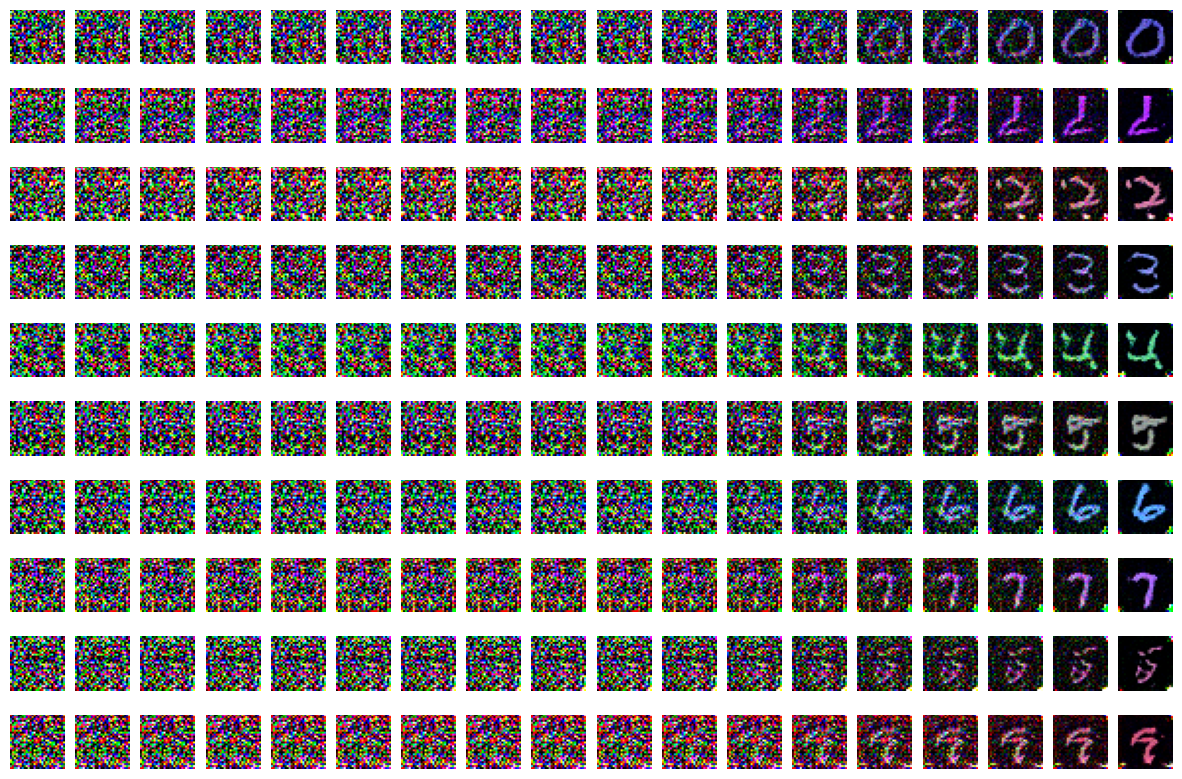

In [8]:
_ = plot_image_evolution(
    images=synthetic_images_t.detach().cpu(),
    n_images=n_images,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500, 550, 600, 650, 700, 720, 750, 770, 800],
    figsize=(15, 10),
)


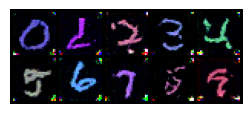

In [9]:
n_rows = 2
n_cols = 5

final_images = synthetic_images_t[..., -1].detach().cpu()

_ = plot_image_grid(
    images = final_images,
    figsize =(3, 3),
    n_rows=n_rows, 
    n_cols=n_cols,
)

In [ ]:
final_images = synthetic_images_t[..., -1]

# Calcular BPD para tus imágenes generadas con modelo condicional
with torch.no_grad():
    bpd_values = odec.compute_bpd_with_ode(
        model=score_model,
        x=final_images,  
        drift_coefficient=vp_drift_coefficient,  
        diffusion_coefficient=diffusion_coefficient,
        sigma_t_func=vp_sigma_t, 
        y=y,
        n_steps=100,  
        seed=42
    )

print(f"\nBPD mean: {bpd_values.mean().item():.4f}")
print(f"BPD std: {bpd_values.std().item():.4f}")


BPD mean: 3.7800
BPD std: 1.2220
